In [48]:
from langchain_core.prompts import *
from langchain_core.messages import *
from langchain_core.output_parsers import *
from langchain_openai import ChatOpenAI
from langchain_core.runnables import *
from pydantic import *
from typing import *
from dotenv import load_dotenv

load_dotenv()
llm =  ChatOpenAI(model="gpt-4o-mini")

# TABLE OF CONTENTS 

1)  **prompt template** 
2)  **Messages**  
    -  System | AI | Human 
3)  **output parsers**  
    -  Str |  Json |  Pydantic 

4)  **with Structured  output** 
    -  Typed dict/pydantic model |  Json object 


5)  **Runnables** 
    -  Runnable sequnece/parallel/passthrough/branch/lambda 



## 1)  Prompt template 

**Normal Prompt template**

- invoking 
- saving and loading 

In [49]:
prompt_template =  PromptTemplate(template="write 5 ideas on {context}",
                                  input_variables=["context"])

prompt =  prompt_template.invoke({"context":"tech business"})


print(llm.invoke(prompt).content)

# prompt_template.save("template.json")
# prompt =  load_prompt("template.json")

Sure! Here are five tech business ideas that could be explored:

1. **Telehealth Platform for Mental Health**:
   Develop a telehealth platform focused on mental health services, connecting users with licensed therapists and counselors through video, chat, and phone calls. The platform can include AI-driven tools for mood tracking, resource sharing, and even virtual support groups, ensuring accessibility and privacy for users seeking mental health assistance.

2. **AI-Powered Personal Finance Management**:
   Create an app that uses AI to help users manage their finances by analyzing spending habits, providing budget recommendations, and offering personalized investment advice. The app could integrate with bank accounts and offer features like goal setting, actionable savings tips, and alerts for unusual spending patterns.

3. **Smart Home Energy Management System**:
   Launch a smart energy management system that allows homeowners to monitor and control their energy consumption remote

**ChatPromptTemplate**

In [50]:
prompt_template =  ChatPromptTemplate([
    ('system',"you are geneator of ideas of {domain}"),
    ('user','generate ideas on your domain of count {count}')
])


prompt =  prompt_template.invoke({"domain":"tech","count":5})
print(prompt)

messages=[SystemMessage(content='you are geneator of ideas of tech', additional_kwargs={}, response_metadata={}), HumanMessage(content='generate ideas on your domain of count 5', additional_kwargs={}, response_metadata={})]


## 2)  Messages 

In [51]:
messages = [
    SystemMessage(content="You are a loan score decider and you have to decide loan only above 750 and reject below 400"),
    HumanMessage(content="My credit score is 350. Am I eligible for the loan? ")
]

result = llm.invoke(messages)

messages.append(AIMessage(content=result.content))


for x in messages :
    print(x)

content='You are a loan score decider and you have to decide loan only above 750 and reject below 400' additional_kwargs={} response_metadata={}
content='My credit score is 350. Am I eligible for the loan? ' additional_kwargs={} response_metadata={}
content='No, you are not eligible for the loan because your credit score is below the required minimum of 400.' additional_kwargs={} response_metadata={} tool_calls=[] invalid_tool_calls=[]


## 3)  Output parsers 

- Str parser 
- Json parser 
-  pydantic parser 


### 1)  Str output parser

In [52]:
prompt =  PromptTemplate(template="write 5 lines on {topic}",input_variables=['topic'])
str_parser =  StrOutputParser()


chain =  prompt |  llm   | str_parser

result =  chain.invoke({"topic":"solar system"})
print(result)

The solar system is a vast celestial region that consists of the Sun and the objects bound to it by gravity. Eight major planets, including Mercury, Venus, Earth, Mars, Jupiter, Saturn, Uranus, and Neptune, orbit the Sun along with their moons. Dwarf planets like Pluto, asteroids, and comets also populate this intricate system. The solar system formed approximately 4.6 billion years ago from a rotating disk of gas and dust. It is part of the Milky Way galaxy and continues to be a subject of exploration and scientific discovery.


### 2)  Json output parser

In [53]:

# Here, a partial variable, that is, parser gets format instructions. Just convert a string to JSON. 
parser = JsonOutputParser()

prompt = PromptTemplate(
    template="Give the title, director and release year of a popular {genre} movie.\n{format_instructions}",
    input_variables=["genre"],
    partial_variables={"format_instructions": parser.get_format_instructions()},
)

chain = prompt | llm | parser
result = chain.invoke({"genre": "sci-fi"})

print(result)
print(type(result))

{'title': 'Inception', 'director': 'Christopher Nolan', 'release_year': 2010}
<class 'dict'>


### 3)  pydantic output parser

In [54]:
class Person(BaseModel):

    name: str = Field(description='Name of the person')
    age: int = Field(gt=18, description='Age of the person')
    city: str = Field(description='Name of the city the person belongs to')

parser = PydanticOutputParser(pydantic_object=Person)



# here partial function format data according to pydantic model 
template = PromptTemplate(
    template='Generate the name, age and city of a fictional {place} person \n {format_instruction}',
    input_variables=['place'],
    partial_variables={'format_instruction':parser.get_format_instructions()}
)

chain = template | llm | parser

final_result = chain.invoke({'place':'sri lankan'})

print(final_result)
print(type(final_result))

name='Nimali Perera' age=27 city='Colombo'
<class '__main__.Person'>


## 4)  With structured output parsers 

-  Typed dict /  pydantic model
-  Json Object 

### 1)  Typed dict / pydantic model 

In [55]:
class Student(TypedDict):
    name  : str
    class_ :  str
    age  : int 
    

model =  llm.with_structured_output(Student)

result =  model.invoke("My name is Rishabh, and I study in the civil section. My age is currently around 19. ")

print(result)

{'name': 'Rishabh', 'class_': 'civil', 'age': 19}


### 2)  Json Model

In [56]:
json_object = {
    "title": "Student",
    "description": "details about a student",
    "type": "object",                 # added
    "properties": {                   # added: the fields now go inside this
        "name": {
            "type": "string"          # was "str"
        },
        "age": {
            "type": "integer"         # was "int"
        },
        "fav_subjects": {
            "type": "array",
            "items": {"type": "string"}   # added
        }
    },                                # properties ends here
    "required": ["name", "age"]       # stays outside properties
}

model = llm.with_structured_output(json_object)

result = model.invoke("My name is Rishabh, and I study in the civil section. My age is currently around 19.")

print(result)

{'name': 'Rishabh', 'age': 19, 'fav_subjects': ['Civil Engineering', 'Mathematics', 'Environmental Science']}


# 5)  Runnables 

- RunnableSequence
- Runnable Parallel
- RunnablePassthrough [not coded]
- RunnableLambda [not coded]
- RunnableBranch [not coded]



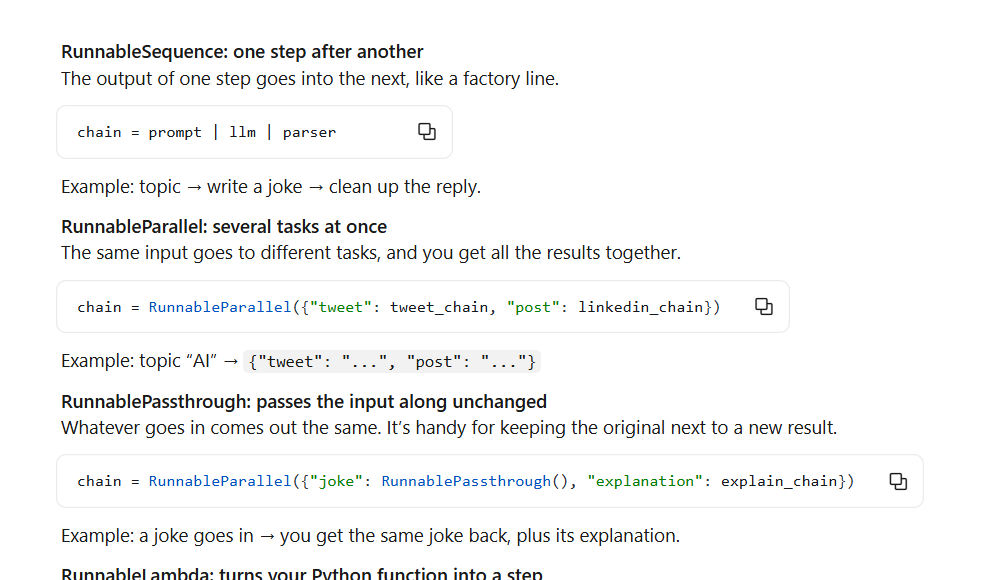
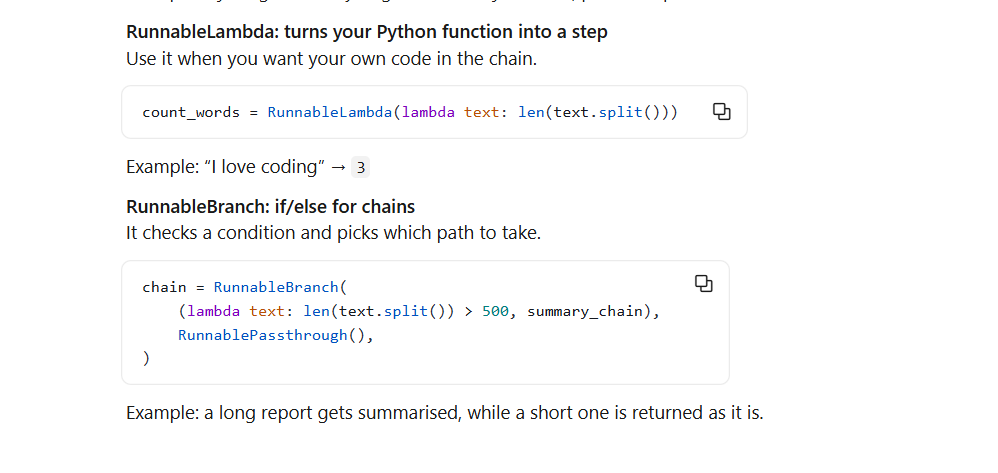


### 1)  Runnable sequence 

In [57]:
prompt =  PromptTemplate(template="write 5 lines on {topic}",input_variables=['topic'])
str_parser =  StrOutputParser()



sequence =  RunnableSequence(prompt,llm,str_parser)

print(sequence.invoke({"topic":"solar system"}))

The solar system consists of the Sun, eight planets, and various celestial bodies, including moons, asteroids, and comets. The planets are divided into two categories: terrestrial planets like Earth and Mars, and gas giants like Jupiter and Saturn. Each planet has its own unique characteristics, with diverse atmospheres, temperatures, and landscapes. The solar system formed about 4.6 billion years ago from a giant cloud of gas and dust. Exploring our solar system continues to reveal insights about the origins of life and the universe.


### 2)  Runnable parallel

In [58]:
prompt1 = PromptTemplate(
    template='Generate 5 lines {topic}',
    input_variables=['topic']
)

prompt2 = PromptTemplate(
    template='Generate similar topics about  {topic}',
    input_variables=['topic']
)


parser = StrOutputParser()

parallel_chain = RunnableParallel({
    'topics': RunnableSequence(prompt1, llm, parser),
    'similar_topics': RunnableSequence(prompt2, llm, parser)
})

result = parallel_chain.invoke({'topic':'AI'})

print(result['topics'])
print(result['similar_topics'])


Sure! Here are five lines of AI-generated text:

1. In the heart of the sprawling city, a lone musician strummed her guitar, weaving melodies that danced with the whispers of the evening breeze.
2. As the sun dipped below the horizon, painting the sky in hues of orange and pink, memories of summer laughter echoed through the air.
3. The ancient oak tree stood sentinel in the meadow, its gnarled branches a testament to the passage of time and the stories etched into its bark.
4. Underneath the silver glow of the moon, a group of friends shared secrets and dreams, their laughter mingling with the nocturnal symphony of crickets.
5. In a world where technology and nature coexisted, the hum of electric vehicles blended harmoniously with the rustle of leaves, creating a new rhythm of life.
Sure! Here are some interesting topics related to artificial intelligence:

1. **Ethical Implications of AI in Decision-Making**: Analyzing how AI systems can influence moral choices in sectors like health